# Imports Libraries & Tools

In [73]:
import os  # For directory and file operations
import sys  # For adding the project root to the Python import path
import numpy as np  # For numerical operations and handling image arrays
import random  # For generating random values for augmentation
from PIL import Image, ImageEnhance  # For image processing and enhancement
from tensorflow.keras.preprocessing.image import load_img  # For loading images
from tensorflow.keras.models import Sequential  # For building the model
from tensorflow.keras.layers import Input, Flatten, Dropout, Dense  # For model layers
from tensorflow.keras.optimizers import Adam  # For optimizer
from tensorflow.keras.applications import VGG16  # For using VGG16 model
from sklearn.utils import shuffle  # For shuffling the data

# Add the project root to sys.path so the local 'src' package can be imported
sys.path.append(os.path.abspath(".."))

from src.config import RAW_DATA_DIR, PROCESSED_DATA_DIR, VALID_EXTENSIONS  # Project configuration paths

### Extension validation

In [74]:

def is_valid_extension(file_path):
    """
    Vérifie si le fichier possède une extension d'image valide 
    (insensible à la casse : .JPG, .png, etc.).
    """
    return file_path.lower().endswith(VALID_EXTENSIONS)
valid_paths = []
invalid_count = 0

for root, dirs, files in os.walk(RAW_DATA_DIR):
    for file_name in files:
        file_path = os.path.join(root, file_name)
        
        # 1. Validation de l'extension
        if not is_valid_extension(file_path):
            invalid_count += 1
            continue  # Ignore et passe au fichier suivant
            
        valid_paths.append(file_path)

print(f"Fichiers valides retenus : {len(valid_paths)}")
print(f"Fichiers ignorés (mauvaise extension) : {invalid_count}")   

Fichiers valides retenus : 7023
Fichiers ignorés (mauvaise extension) : 0


### Loading Dataset

In [75]:
train_paths = []
train_labels = []

# Load and shuffle train data
for label in os.listdir(RAW_DATA_DIR):
    for image in os.listdir(os.path.join(RAW_DATA_DIR, label)):
        train_paths.append(os.path.join(RAW_DATA_DIR, label, image))
        train_labels.append(label)
train_paths, train_labels = shuffle(train_paths, train_labels)
print(train_labels)
print(train_paths)

# Load and shuffle test data
test_paths = []
test_labels = []


for label in os.listdir(RAW_DATA_DIR):
    for image in os.listdir(os.path.join(RAW_DATA_DIR, label)):
        test_paths.append(os.path.join(RAW_DATA_DIR, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)

print(test_labels)
print(test_paths)


['meningioma', 'pituitary', 'notumor', 'glioma', 'notumor', 'meningioma', 'pituitary', 'pituitary', 'glioma', 'notumor', 'notumor', 'notumor', 'notumor', 'notumor', 'pituitary', 'meningioma', 'glioma', 'glioma', 'glioma', 'meningioma', 'glioma', 'meningioma', 'pituitary', 'notumor', 'glioma', 'glioma', 'notumor', 'notumor', 'glioma', 'pituitary', 'pituitary', 'glioma', 'glioma', 'notumor', 'glioma', 'glioma', 'meningioma', 'notumor', 'notumor', 'notumor', 'pituitary', 'meningioma', 'meningioma', 'pituitary', 'notumor', 'notumor', 'meningioma', 'notumor', 'meningioma', 'pituitary', 'glioma', 'glioma', 'notumor', 'notumor', 'glioma', 'notumor', 'pituitary', 'glioma', 'glioma', 'glioma', 'notumor', 'meningioma', 'notumor', 'meningioma', 'meningioma', 'meningioma', 'notumor', 'glioma', 'meningioma', 'notumor', 'notumor', 'notumor', 'notumor', 'glioma', 'pituitary', 'pituitary', 'notumor', 'pituitary', 'notumor', 'glioma', 'pituitary', 'pituitary', 'meningioma', 'glioma', 'meningioma', 'gli

### Data visualization

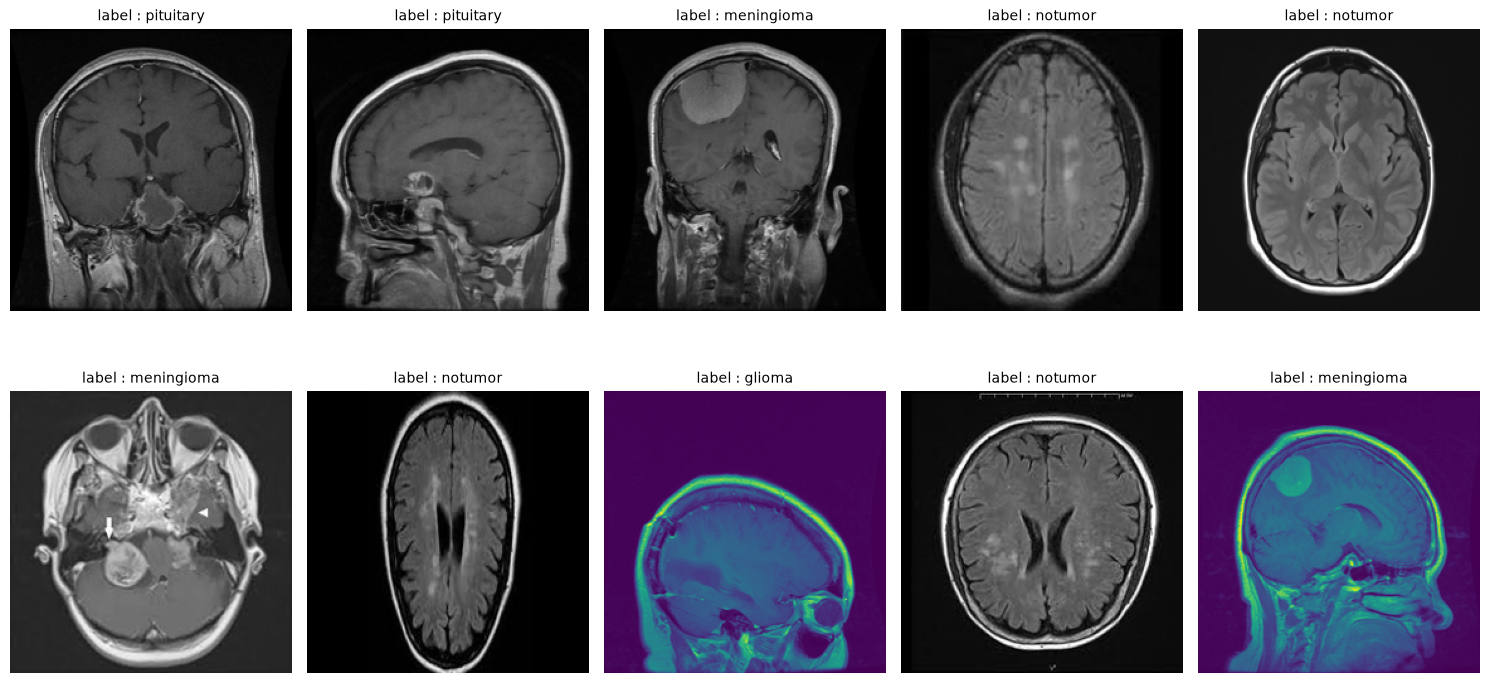

In [76]:
import random
from PIL import Image
import matplotlib.pyplot as plt
import os

# select 10 random indices to visualize 10 images

random_indices = random.sample(range(len(train_paths)), 10)
fig, axes = plt.subplots(2, 5, figsize=(15, 8))
axes = axes.ravel()
for i, idx in enumerate(random_indices):
    img_path = train_paths[idx]
    img = Image.open(img_path)
    img = img.resize((224, 224))

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"label : {train_labels[idx]}", fontsize=10)

plt.tight_layout()
plt.show()

### Image preprocessing (Helper functions)

In [77]:
# Image augmentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    image = np.array(image)
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image = augment_image(image)
        images.append(image)
    return np.array(images)

# Encoding labels (convert label names to integers)
def encode_label(labels):
    unique_labels = os.listdir(RAW_DATA_DIR)  # Ensure unique labels are determined
    encoded = [unique_labels.index(label) for label in labels]
    return np.array(encoded)

# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch


### Model

In [78]:
IMAGE_SIZE = 128
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')

for layer in base_model.layers:
    layer.trainable = False

base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))
model.add(base_model)
model.add(Flatten())
model.add(Dropout(0.3))

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(len(os.listdir(RAW_DATA_DIR)), activation='softmax'))

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

batch_size = 20

steps = int(len(train_paths)/ batch_size)

epochs = 5


history = model.fit(
    datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
    steps_per_epoch=steps,
    epochs=epochs
)


Epoch 1/5


/home/moali/projects/brainscan/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792090775.356023   79349 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


351/351 ━━━━━━━━━━━━━━━━━━━━ 206s 582ms/step - loss: 0.7373 - sparse_categorical_accuracy: 0.7664
Epoch 2/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 205s 586ms/step - loss: 0.3588 - sparse_categorical_accuracy: 0.8699
Epoch 3/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 213s 607ms/step - loss: 0.2580 - sparse_categorical_accuracy: 0.9018
Epoch 4/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 209s 594ms/step - loss: 0.1905 - sparse_categorical_accuracy: 0.9273
Epoch 5/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 212s 605ms/step - loss: 0.1669 - sparse_categorical_accuracy: 0.9433


### Model evaluation

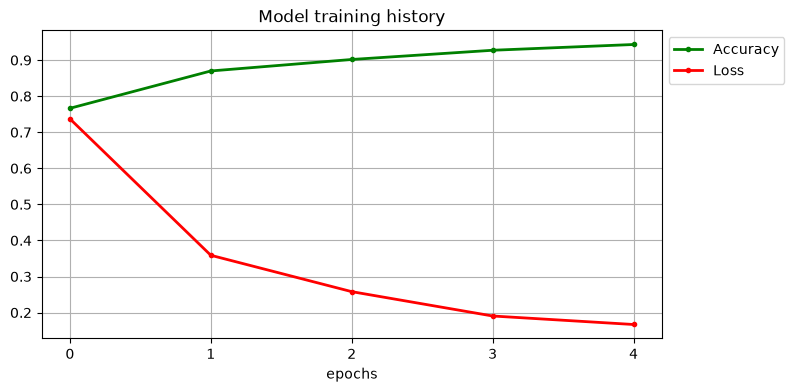

In [84]:
# type(history)

plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'], '.g-', linewidth=2)
plt.plot(history.history['loss'], '.r-', linewidth=2)
plt.title('Model training history')
plt.xlabel('epochs')
plt.xticks([x for x in range(epochs)])
plt.legend(['Accuracy', 'Loss'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()


### Model classification reports

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, auc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import label_binarize
import numpy as np

test_images = open_images(test_paths)
test_labels_encoded = encode_label(test_labels)

test_predictions = model.predict(test_images)

print("Classification report is : ")
print(classification_report(test_labels, np.argmax(test_predictions, axis=1)))